# Task 1 — From Two Spreadsheets to a Product Recommender 🛒

**Goal:** merge `customer_social_profiles` with `customer_transactions`, engineer features, and train the **Product Recommendation Model**, which predicts the product category a customer will buy when they visit our social media pages.

**Where this fits in the system flow:**

```
Face recognised ─► [THIS NOTEBOOK: product model predicts] ─► Voice approves ─► Prediction shown
      │                                                           │
      └──── not recognised ─► ACCESS DENIED        voice rejected ─┘─► ACCESS DENIED
```

The face and voice models belong to my teammates. My job is the model in the middle, so its output needs to be **trustworthy, honestly evaluated, and easy to call** from the command-line app.

**Roadmap:** load → inspect → EDA → clean → validate key → aggregate & merge → feature engineering → model comparison → tuning → evaluation → save model + feature store → demo call.

## Before running

1. Export the [customer social profiles spreadsheet](https://docs.google.com/spreadsheets/d/10up-WdC0a6egYaXLKiMQUotpOvaKZRZvYuWFQx4-RPQ/edit?gid=862127784#gid=862127784) as `customer_social_profiles.csv`.
2. Export the [customer transactions spreadsheet](https://docs.google.com/spreadsheets/d/1s4WOVm49lmLQ8d9QbbbdgAcRTNh3m0KCH_5ciiaRZw0/edit?gid=1844409263#gid=1844409263) as `customer_transactions.csv`.
3. Put both in the `data/` folder next to this notebook (or edit the paths in the setup cell).
4. Install dependencies: `pip install -r requirements.txt`.

## 1. Setup — libraries, paths and a fixed random seed

pandas handles the tables, seaborn/matplotlib the plots, and scikit-learn the models. I fix `RANDOM_STATE` so the splits and forests come out the same on every run, which means the numbers in my report match the notebook.

In [1]:
from pathlib import Path
import json
import re

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, classification_report,
                             f1_score, log_loss, make_scorer, top_k_accuracy_score)
from sklearn.model_selection import (GridSearchCV, RepeatedStratifiedKFold,
                                     cross_validate, train_test_split)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

sns.set_theme(style="whitegrid", palette="deep")
RANDOM_STATE = 42

DATA_DIR = Path("data")
MODEL_DIR = Path("models")
SOCIAL_PATH = DATA_DIR / "customer_social_profiles.csv"
TRANSACTIONS_PATH = DATA_DIR / "customer_transactions.csv"
MERGED_PATH = DATA_DIR / "merged_customer_transactions_social.csv"   # merged + engineered features
FEATURE_STORE_PATH = DATA_DIR / "customer_feature_store.csv"           # latest state per customer (for the CLI)
MODEL_PATH = MODEL_DIR / "product_recommender.joblib"

print("scikit-learn", sklearn.__version__, "| pandas", pd.__version__)
print("Social profiles file:", SOCIAL_PATH.resolve())
print("Transactions file:  ", TRANSACTIONS_PATH.resolve())

scikit-learn 1.9.0 | pandas 3.0.3
Social profiles file: C:\Users\pc\yusuf_school\machineLearningPipeline_formative2MultimodalDataPreprocessingAssignment\data\customer_social_profiles.csv
Transactions file:   C:\Users\pc\yusuf_school\machineLearningPipeline_formative2MultimodalDataPreprocessingAssignment\data\customer_transactions.csv


## 2. Load the CSVs and standardise column names

Headers get converted to `snake_case`, so a stray space or capital letter can't break a column lookup later. If two headers end up with the same name after cleaning, the loader stops instead of silently overwriting one of them.

In [2]:
def normalize_column_name(column):
    # "Customer ID (new)" -> "customer_id_new"
    name = re.sub(r"[^a-z0-9]+", "_", str(column).strip().lower())
    return name.strip("_")


def load_and_standardize_csv(path):
    # Fail loudly with a helpful message if the export is missing
    if not path.is_file():
        raise FileNotFoundError(f"CSV not found: {path.resolve()} (cwd = {Path.cwd()})")
    frame = pd.read_csv(path)
    frame.columns = [normalize_column_name(c) for c in frame.columns]
    if frame.columns.duplicated().any():
        raise ValueError(f"Duplicate headers after normalising: {frame.columns[frame.columns.duplicated()].tolist()}")
    return frame


social_raw = load_and_standardize_csv(SOCIAL_PATH)
transactions_raw = load_and_standardize_csv(TRANSACTIONS_PATH)
print("Social profiles:", social_raw.shape, "| Transactions:", transactions_raw.shape)

Social profiles: (155, 5) | Transactions: (150, 6)


## 3. First look — samples, statistics, missing values, duplicates

Before plotting anything I want to know what each table contains. The loop below prints sample rows, summary statistics, missing counts and exact-duplicate counts for both files.

In [3]:
for table_name, frame in [("Social profiles", social_raw), ("Transactions", transactions_raw)]:
    print(f"\n=== {table_name} ===")
    display(frame.head(3))
    display(frame.describe(include="all").T)
    print("Missing values:", frame.isna().sum()[frame.isna().sum() > 0].to_dict() or "none")
    print("Exact duplicate rows:", int(frame.duplicated().sum()))

print("\nColumn names shared by both files:", sorted(set(social_raw.columns) & set(transactions_raw.columns)) or "none")


=== Social profiles ===


,customer_id_new,social_media_platform,engagement_score,purchase_interest_score,review_sentiment
0,A178,LinkedIn,74,4.9,Positive
1,A190,Twitter,82,4.8,Neutral
2,A150,Facebook,96,1.6,Positive


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customer_id_new,155,84,A155,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
social_media_platform,155,5,Twitter,38,NaN,NaN,NaN,NaN,NaN,NaN,NaN
engagement_score,155.0,NaN,NaN,NaN,75.606452,14.568021,50.0,63.5,77.0,87.5,99.0
purchase_interest_score,155.0,NaN,NaN,NaN,3.152903,1.142867,1.0,2.35,3.2,4.1,5.0
review_sentiment,155,3,Positive,63,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Missing values: none
Exact duplicate rows: 5

=== Transactions ===


,customer_id_legacy,transaction_id,purchase_amount,purchase_date,product_category,customer_rating
0,151,1001,408,2024-01-01,Sports,2.3
1,192,1002,332,2024-01-02,Electronics,4.2
2,114,1003,442,2024-01-03,Electronics,2.1


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customer_id_legacy,150.0,NaN,NaN,NaN,148.76,30.046425,100.0,121.25,150.5,174.75,199.0
transaction_id,150.0,NaN,NaN,NaN,1075.5,43.445368,1001.0,1038.25,1075.5,1112.75,1150.0
purchase_amount,150.0,NaN,NaN,NaN,280.78,121.329595,51.0,179.0,274.0,388.5,495.0
purchase_date,150,150,2024-01-01,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
product_category,150,5,Sports,35,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_rating,140.0,NaN,NaN,NaN,2.985,1.20699,1.0,1.95,3.0,4.0,5.0


Missing values: {'customer_rating': 10}
Exact duplicate rows: 0

Column names shared by both files: none


### Variable types: what each column *means*, not just its dtype

pandas reports `customer_id_legacy` as `int64`, but averaging customer IDs makes no sense. So I tag every column by its role. Only the **numeric** columns go into the distribution and outlier plots. (The original version of this notebook plotted the ID columns as if they were features, which I fixed here.)

In [4]:
COLUMN_ROLES = {
    "customer_id_new": "identifier", "customer_id_legacy": "identifier", "transaction_id": "identifier",
    "social_media_platform": "categorical", "review_sentiment": "categorical (ordinal)",
    "product_category": "categorical — TARGET", "purchase_date": "date",
    "engagement_score": "numeric", "purchase_interest_score": "numeric",
    "purchase_amount": "numeric", "customer_rating": "numeric",
}
types_table = pd.concat([
    pd.DataFrame({"table": name, "column": f.columns, "pandas_dtype": f.dtypes.astype(str).values,
                  "n_unique": f.nunique().values})
    for name, f in [("social", social_raw), ("transactions", transactions_raw)]
])
types_table["role"] = types_table["column"].map(COLUMN_ROLES)
display(types_table.reset_index(drop=True))

,table,column,pandas_dtype,n_unique,role
0,social,customer_id_new,str,84,identifier
1,social,social_media_platform,str,5,categorical
2,social,engagement_score,int64,50,numeric
3,social,purchase_interest_score,float64,40,numeric
4,social,review_sentiment,str,3,categorical (ordinal)
5,transactions,customer_id_legacy,int64,75,identifier
6,transactions,transaction_id,int64,150,identifier
7,transactions,purchase_amount,int64,120,numeric
8,transactions,purchase_date,str,150,date
9,transactions,product_category,str,5,categorical — TARGET


## 4. Exploratory Data Analysis

### Plot 1 — Distributions of the real numeric features

One histogram per meaningful numeric column, with a KDE curve on top. I'm checking for skew, extra peaks, and odd values such as ratings outside 1–5.

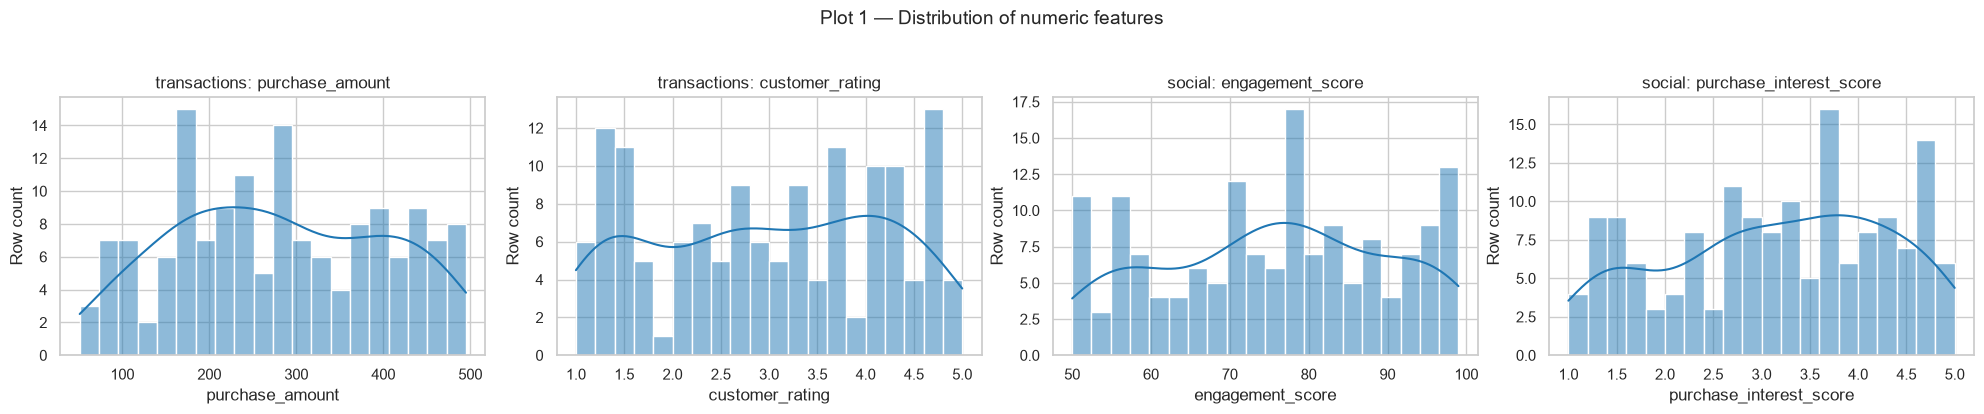

,skewness
purchase_amount,0.06
customer_rating,-0.08
engagement_score,-0.11
purchase_interest_score,-0.23


In [5]:
NUMERIC_FEATURES = [("transactions", "purchase_amount"), ("transactions", "customer_rating"),
                    ("social", "engagement_score"), ("social", "purchase_interest_score")]
tables = {"transactions": transactions_raw, "social": social_raw}

fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, (tname, col) in zip(axes, NUMERIC_FEATURES):
    sns.histplot(tables[tname][col].dropna(), bins=20, kde=True, ax=ax, color="tab:blue")
    ax.set(title=f"{tname}: {col}", xlabel=col, ylabel="Row count")
fig.suptitle("Plot 1 — Distribution of numeric features", y=1.03, fontsize=14)
plt.tight_layout(); plt.show()

# Skewness near 0 = roughly symmetric
display(pd.Series({col: tables[t][col].skew() for t, col in NUMERIC_FEATURES}, name="skewness").round(2).to_frame())

**What I see:** all four features are spread fairly evenly across their ranges, with no single bell curve and skewness close to 0 (between −0.23 and 0.06). There are no impossible values. These flat shapes look like synthetic data, so I don't expect any single feature to separate the classes strongly. No log-transform is needed.

### Plot 2 — Boxplots and an IQR outlier check

Boxplots show values beyond 1.5×IQR as dots. Next to them, a table counts those points so I'm not just eyeballing. If a value is inside the valid range (for example a rating between 1 and 5), I treat it as real behaviour and keep it.

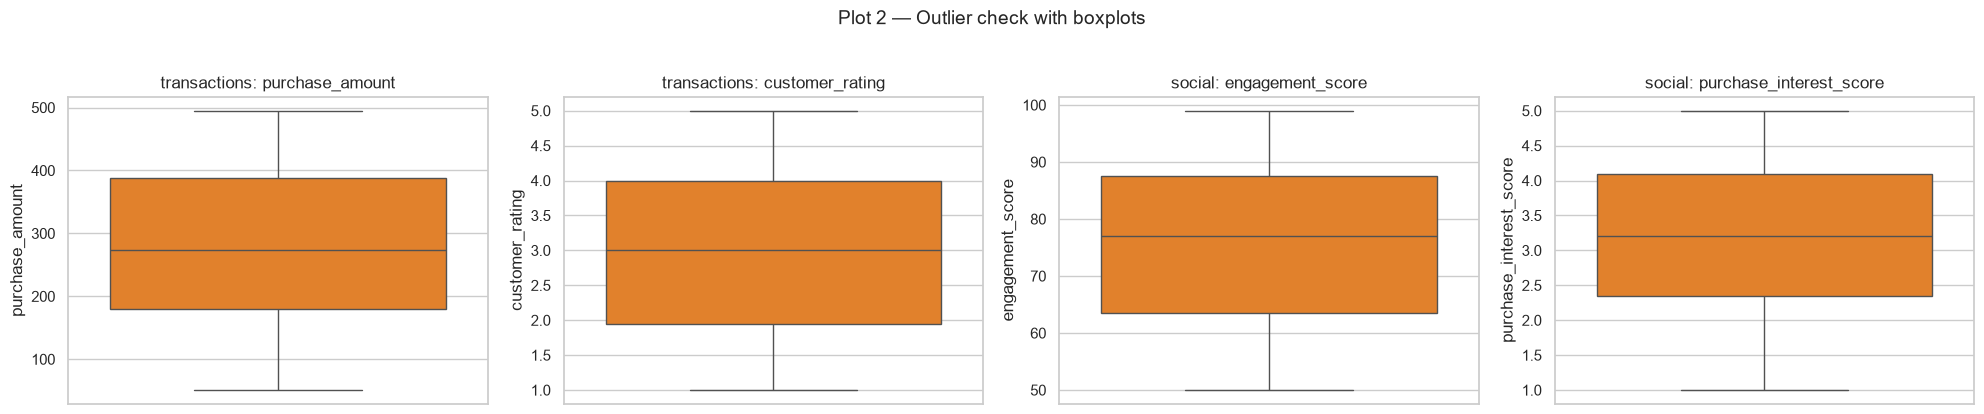

,feature,min,max,iqr_lower,iqr_upper,n_outliers
0,purchase_amount,51.0,495.0,-135.25,702.75,0
1,customer_rating,1.0,5.0,-1.12,7.07,0
2,engagement_score,50.0,99.0,27.50,123.50,0
3,purchase_interest_score,1.0,5.0,-0.28,6.72,0


In [6]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
outlier_rows = []
for ax, (tname, col) in zip(axes, NUMERIC_FEATURES):
    values = tables[tname][col].dropna()
    sns.boxplot(y=values, ax=ax, color="tab:orange")
    ax.set(title=f"{tname}: {col}", ylabel=col)
    q1, q3 = values.quantile([0.25, 0.75])
    low, high = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    outlier_rows.append({"feature": col, "min": values.min(), "max": values.max(),
                         "iqr_lower": low, "iqr_upper": high,
                         "n_outliers": int(((values < low) | (values > high)).sum())})
fig.suptitle("Plot 2 — Outlier check with boxplots", y=1.03, fontsize=14)
plt.tight_layout(); plt.show()
display(pd.DataFrame(outlier_rows).round(2))

**What I see:** **zero** IQR outliers in all four features, and every value is inside its valid range (checked again in Section 5b). So I remove nothing. Clipping would only throw away real customers from an already small dataset.

### Plot 3 — The target: which products do people buy?

This is the most important plot for modelling. If one category dominated, a model could score high accuracy just by always guessing it. The right panel checks whether spend differs by category.

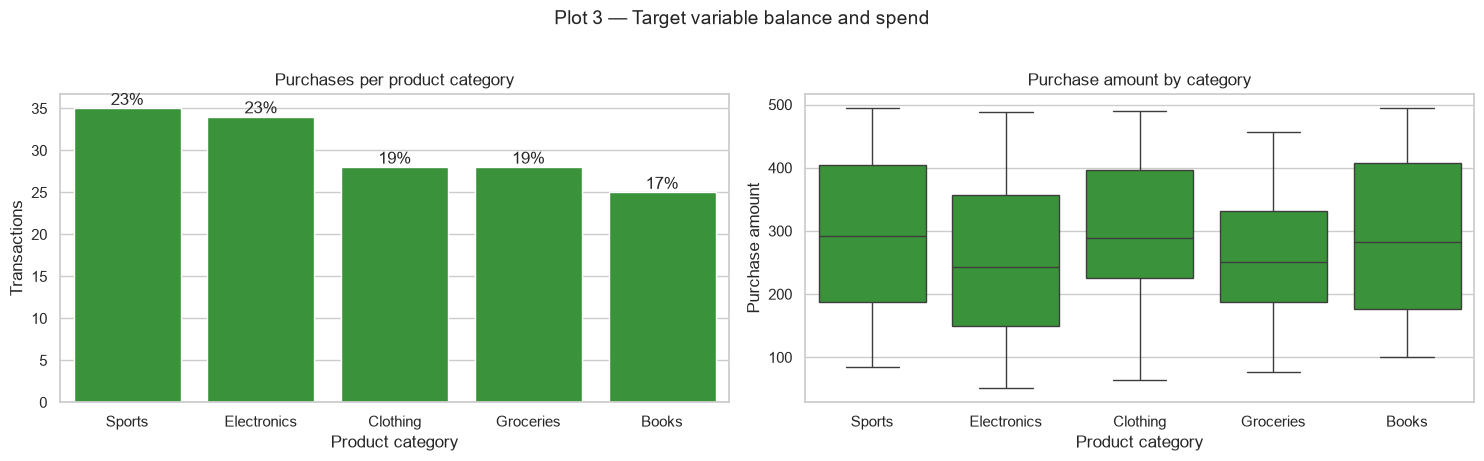

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
order = transactions_raw["product_category"].value_counts().index

sns.countplot(data=transactions_raw, x="product_category", order=order, ax=axes[0], color="tab:green")
axes[0].set(title="Purchases per product category", xlabel="Product category", ylabel="Transactions")
for p in axes[0].patches:  # label every bar with its share of all purchases
    axes[0].annotate(f"{p.get_height() / len(transactions_raw):.0%}", (p.get_x() + p.get_width() / 2, p.get_height()),
                     ha="center", va="bottom")

sns.boxplot(data=transactions_raw, x="product_category", y="purchase_amount", order=order, ax=axes[1], color="tab:green")
axes[1].set(title="Purchase amount by category", xlabel="Product category", ylabel="Purchase amount")
fig.suptitle("Plot 3 — Target variable balance and spend", y=1.02, fontsize=14)
plt.tight_layout(); plt.show()

**What I see:** the five categories are close to balanced (17%–23%), so accuracy is a fair metric. The bar to beat is **~23%**, what you'd get by always guessing "Sports". Medians of spend sit between about 240 and 290 for every category and the boxes overlap heavily, so purchase amount alone can't tell categories apart.

### Plot 4 — Social-media side: platforms and sentiment

These two categorical columns will later become numeric features, so I want to know how many levels each has and whether any level is rare.

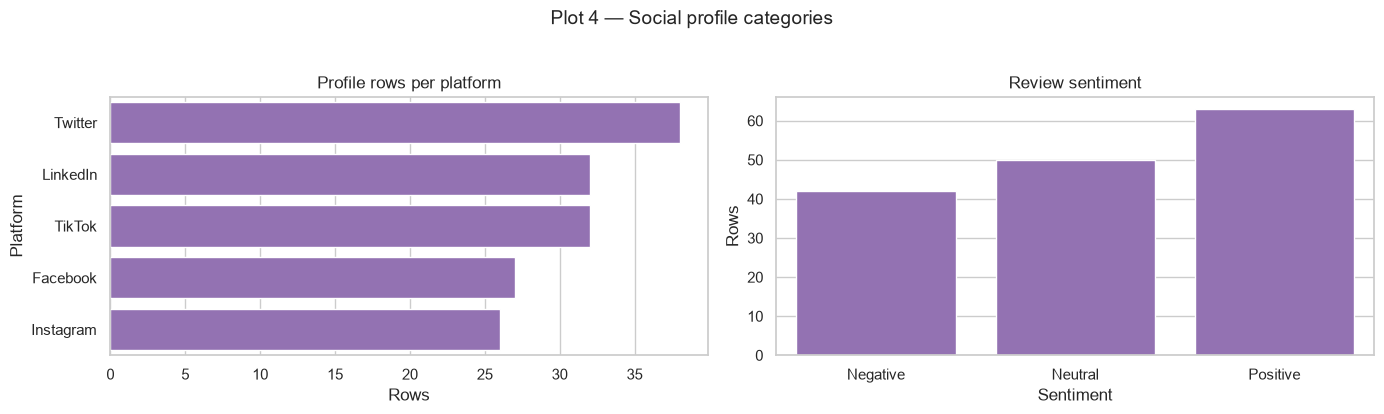

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.countplot(data=social_raw, y="social_media_platform", order=social_raw["social_media_platform"].value_counts().index,
              ax=axes[0], color="tab:purple")
axes[0].set(title="Profile rows per platform", xlabel="Rows", ylabel="Platform")
sns.countplot(data=social_raw, x="review_sentiment", order=["Negative", "Neutral", "Positive"], ax=axes[1], color="tab:purple")
axes[1].set(title="Review sentiment", xlabel="Sentiment", ylabel="Rows")
fig.suptitle("Plot 4 — Social profile categories", y=1.03, fontsize=14)
plt.tight_layout(); plt.show()

**What I see:** the five platforms are evenly represented (26–35 rows each, after removing duplicates) and sentiment leans Positive (60) > Neutral (49) > Negative (41). No level is rare enough to cause trouble when encoded, so I keep all five platforms as share features.

## 5. Cleaning

### 5a. Exact duplicates

I drop rows that are identical in **every** column, because those are copy-paste errors. Rows that only share a customer ID stay: one customer can make several purchases or have accounts on several platforms.

In [9]:
def drop_exact_duplicates(frame, table_name):
    n_dupes = int(frame.duplicated().sum())
    print(f"{table_name}: removed {n_dupes} exact duplicate row(s)")
    return frame.drop_duplicates().reset_index(drop=True)


social = drop_exact_duplicates(social_raw, "Social profiles")
transactions = drop_exact_duplicates(transactions_raw, "Transactions")

Social profiles: removed 5 exact duplicate row(s)
Transactions: removed 0 exact duplicate row(s)


### 5b. Fix types, tidy text, check value ranges

`purchase_date` is converted to a real datetime, which the time features need later. Text categories get trimmed. Each numeric column is checked against its valid range, so a typo like a rating of 50 would stop the notebook.

In [10]:
transactions["purchase_date"] = pd.to_datetime(transactions["purchase_date"], errors="raise")
for frame, cols in [(social, ["social_media_platform", "review_sentiment"]), (transactions, ["product_category"])]:
    for col in cols:
        frame[col] = frame[col].astype("string").str.strip()

VALID_RANGES = {("transactions", "customer_rating"): (1, 5), ("transactions", "purchase_amount"): (0, None),
                ("social", "engagement_score"): (0, 100), ("social", "purchase_interest_score"): (0, 5)}
for (tname, col), (low, high) in VALID_RANGES.items():
    values = {"transactions": transactions, "social": social}[tname][col].dropna()
    bad = (values < low) | ((values > high) if high is not None else False)
    assert not bad.any(), f"{col} has {int(bad.sum())} out-of-range values"
    print(f"✓ {col}: all values in [{low}, {high if high is not None else '∞'}]")

assert transactions["transaction_id"].is_unique, "transaction_id should identify one purchase"
print("✓ transaction_id is unique | date range:", transactions["purchase_date"].min().date(), "→",
      transactions["purchase_date"].max().date())

✓ customer_rating: all values in [1, 5]
✓ purchase_amount: all values in [0, ∞]
✓ engagement_score: all values in [0, 100]
✓ purchase_interest_score: all values in [0, 5]
✓ transaction_id is unique | date range: 2024-01-01 → 2024-05-29


### 5c. Missing `customer_rating` — flag it now, impute later

10 ratings are missing. I **don't** fill them here: filling with the median of the whole dataset would leak test-set information into training. The missing values stay as NaN, and the imputer *inside* the model pipeline learns its median from training folds only.

In [11]:
missing = transactions["customer_rating"].isna()
print(f"Missing customer_rating: {int(missing.sum())} of {len(transactions)} ({missing.mean():.1%})")
display(transactions.loc[missing, ["transaction_id", "customer_id_legacy", "product_category", "purchase_amount"]].head())

Missing customer_rating: 10 of 150 (6.7%)


,transaction_id,customer_id_legacy,product_category,purchase_amount
38,1039,161,Groceries,77
41,1042,150,Sports,389
42,1043,154,Electronics,335
69,1070,135,Electronics,364
80,1081,189,Books,344


## 6. Build and validate the merge key

The two files name the customer differently: `A178` in profiles and `178` in transactions. I strip the `A` and compare the digits. The regex is strict, so an ID like `B17` or `17x` raises an error instead of quietly failing to match.

In [12]:
SOCIAL_ID, TXN_ID, KEY = "customer_id_new", "customer_id_legacy", "customer_id"

social_ids = social[SOCIAL_ID].astype("string").str.strip()
txn_ids = transactions[TXN_ID].astype("string").str.strip()
social_key = social_ids.str.extract(r"^A(\d+)$", expand=False)    # "A178" -> "178"
txn_key = txn_ids.str.extract(r"^(\d+)$", expand=False)           # "178"  -> "178"

if social_key.isna().any() or txn_key.isna().any():
    raise ValueError(f"Unexpected ID format: {int(social_key.isna().sum())} social, {int(txn_key.isna().sum())} transaction IDs")

social[KEY] = social_key.astype(int)
transactions[KEY] = txn_key.astype(int)

shared = set(social[KEY]) & set(transactions[KEY])
print(f"Customers in profiles: {social[KEY].nunique()} | in transactions: {transactions[KEY].nunique()} | in both: {len(shared)}")
print("ID ranges — profiles:", social[KEY].min(), "–", social[KEY].max(), "| transactions:",
      transactions[KEY].min(), "–", transactions[KEY].max())

Customers in profiles: 84 | in transactions: 75 | in both: 61
ID ranges — profiles: 100 – 199 | transactions: 100 – 199


Both ID ranges cover 100–199, so the `A`-prefix rule clearly describes the same customer population. Because the files share no column names (Section 3), this derived key is the only sensible join, and the strict format check backs it up.

## 7. One row per customer: aggregate the social profiles

Many customers have **several** profile rows (one per platform), sometimes with different scores. If I joined directly, each purchase would be duplicated once per profile row (many-to-many). So I first collapse the profiles to one row per customer, converting text into numeric features a model can use:

- engagement / purchase-interest → **mean and max**
- sentiment → score (Negative −1, Neutral 0, Positive +1) → **mean**
- platform → **share of the customer's profile rows on each platform**

In [13]:
SENTIMENT_SCORE = {"Negative": -1, "Neutral": 0, "Positive": 1}
social["sentiment_score"] = social["review_sentiment"].map(SENTIMENT_SCORE)
assert social["sentiment_score"].notna().all(), "Unknown sentiment label found"

profile_features = social.groupby(KEY).agg(
    engagement_mean=("engagement_score", "mean"),
    engagement_max=("engagement_score", "max"),
    interest_mean=("purchase_interest_score", "mean"),
    interest_max=("purchase_interest_score", "max"),
    sentiment_mean=("sentiment_score", "mean"),
    social_profile_rows=("social_media_platform", "size"),
    n_platforms=("social_media_platform", "nunique"),
    social_platforms=("social_media_platform", lambda s: " | ".join(sorted(s.unique()))),  # readable summary
)
# Share of each platform per customer (rows sum to 1)
platform_share = pd.crosstab(social[KEY], social["social_media_platform"], normalize="index")
platform_share.columns = [f"share_{c.lower()}" for c in platform_share.columns]
profile_features = profile_features.join(platform_share).reset_index()

print("Profile rows → customers:", len(social), "→", len(profile_features))
print("Customers with more than one profile row:", int((profile_features["social_profile_rows"] > 1).sum()))
display(profile_features.head())

Profile rows → customers: 150 → 84
Customers with more than one profile row: 41


,customer_id,engagement_mean,engagement_max,interest_mean,interest_max,sentiment_mean,social_profile_rows,n_platforms,social_platforms,share_facebook,share_instagram,share_linkedin,share_tiktok,share_twitter
0,100,77.000000,81,4.400000,4.4,-0.500000,2,2,Instagram | Twitter,0.000000,0.500000,0.0,0.0,0.500000
1,101,68.000000,68,1.000000,1.0,0.000000,1,1,Twitter,0.000000,0.000000,0.0,0.0,1.000000
2,102,51.000000,51,4.800000,4.8,0.000000,1,1,LinkedIn,0.000000,0.000000,1.0,0.0,0.000000
3,103,64.333333,77,2.866667,3.6,0.333333,3,2,Facebook | Instagram,0.333333,0.666667,0.0,0.0,0.000000
4,104,83.000000,91,2.933333,4.6,-0.666667,3,2,Facebook | Twitter,0.333333,0.000000,0.0,0.0,0.666667


## 8. Merge: transactions ⟵ customer profiles (left join)

**Why a left join on transactions?** Every purchase is a labelled example of "what this customer bought", so none should be lost. `validate="many_to_one"` makes pandas raise an error if the profile side ever has duplicate keys, and `indicator=True` records which purchases found a profile.

In [14]:
merged = transactions.merge(profile_features, on=KEY, how="left", validate="many_to_one", indicator=True)
merged["has_social_profile"] = merged.pop("_merge").eq("both")

# ---- post-merge checks ----
assert len(merged) == len(transactions), "left join must keep every transaction"
assert merged["transaction_id"].is_unique, "a transaction got duplicated"
print("Rows before / after:", len(transactions), "/", len(merged))
print(f"Transactions with a social profile: {int(merged['has_social_profile'].sum())} ({merged['has_social_profile'].mean():.1%})")
print("Customers with transactions but no profile:", merged.loc[~merged["has_social_profile"], KEY].nunique())
print("Profile customers with no transactions:", len(set(profile_features[KEY]) - set(transactions[KEY])))

Rows before / after: 150 / 150
Transactions with a social profile: 117 (78.0%)
Customers with transactions but no profile: 14
Profile customers with no transactions: 23


### Spot-check: recompute one customer by hand

Asserts tell me the shape is right, but are the *values* right? Here I pick the customer with the most profile rows who also bought something, recompute their mean engagement directly from the raw profile table, and compare it with what landed in the merged table.

In [15]:
# Busiest profile customer who ALSO has purchases (some profile customers never bought anything)
candidates = profile_features[profile_features[KEY].isin(transactions[KEY])]
check_id = int(candidates.sort_values("social_profile_rows", ascending=False)[KEY].iloc[0])
by_hand = social.loc[social[KEY] == check_id, "engagement_score"].mean()
in_merged = merged.loc[merged[KEY] == check_id, "engagement_mean"].unique()

display(social.loc[social[KEY] == check_id, [SOCIAL_ID, "social_media_platform", "engagement_score", "review_sentiment"]])
print(f"Customer {check_id}: mean engagement by hand = {by_hand:.2f} | in merged table = {in_merged}")
assert len(in_merged) == 1 and np.isclose(in_merged[0], by_hand)
print("✓ Aggregation and join values verified")

,customer_id_new,social_media_platform,engagement_score,review_sentiment
73,A125,LinkedIn,66,Positive
82,A125,Facebook,56,Neutral
99,A125,Twitter,67,Positive
139,A125,Twitter,77,Positive


Customer 125: mean engagement by hand = 66.50 | in merged table = [66.5]
✓ Aggregation and join values verified


## 9. Feature engineering — what we know *at the moment of the visit*

Here's the logic I care most about. The model runs when a customer is **on our social page, before they buy**. So a feature is only allowed if it would exist at that moment:

| Allowed ✅ | Not allowed ❌ (leakage) |
|---|---|
| social profile features | `purchase_amount` of *this* purchase (unknown yet) |
| how many times they bought **before**, their average past spend / rating | `customer_rating` of *this* purchase (given after buying) |
| the category of their **previous** purchase, days since it | the product they're about to buy (obviously) |
| visit month / weekday | |

`shift()` is what makes this work: each row only sees that customer's *earlier* rows.

In [16]:
def add_history_features(frame):
    # Sort chronologically so "previous" really means earlier in time
    df = frame.sort_values(["purchase_date", "transaction_id"]).copy()
    by_customer = df.groupby(KEY)
    df["prior_purchase_count"] = by_customer.cumcount()                       # purchases before this one
    df["prior_avg_spend"] = by_customer["purchase_amount"].transform(lambda s: s.shift().expanding().mean())
    df["prior_avg_rating"] = by_customer["customer_rating"].transform(lambda s: s.shift().expanding().mean())
    df["last_category"] = by_customer["product_category"].shift().fillna("None").astype(str)
    df["days_since_last_purchase"] = by_customer["purchase_date"].diff().dt.days
    df["visit_month"] = df["purchase_date"].dt.month
    df["visit_dayofweek"] = df["purchase_date"].dt.dayofweek                  # 0 = Monday
    return df.sort_index()


merged = add_history_features(merged)

# Leakage sanity check: a customer's first purchase must have no history at all
first_rows = merged.sort_values("purchase_date").groupby(KEY).head(1)
assert (first_rows["prior_purchase_count"] == 0).all() and (first_rows["last_category"] == "None").all()
print("✓ First purchases carry no history → no peeking into the future")
history_demo_id = int(merged[KEY].value_counts().idxmax())   # customer with the most purchases
print("History of customer", history_demo_id)
display(merged.loc[merged[KEY] == history_demo_id].sort_values("purchase_date")[["purchase_date", "product_category", "prior_purchase_count",
                                              "prior_avg_spend", "last_category", "days_since_last_purchase"]])

✓ First purchases carry no history → no peeking into the future
History of customer 161


,purchase_date,product_category,prior_purchase_count,prior_avg_spend,last_category,days_since_last_purchase
37,2024-02-07,Clothing,0,NaN,None,NaN
38,2024-02-08,Groceries,1,333.000000,Clothing,1.0
40,2024-02-10,Electronics,2,205.000000,Groceries,2.0
84,2024-03-25,Sports,3,167.666667,Electronics,44.0
93,2024-04-03,Groceries,4,163.250000,Sports,9.0
133,2024-05-13,Sports,5,151.200000,Groceries,40.0


The table above follows our most loyal customer through time. Each row's history columns only describe the rows *above* it, which is exactly the "no time travel" rule.

### Save the merged + engineered dataset

This is the "merged dataset with feature engineering" deliverable. The raw ID columns stay in the file so anyone can audit the join.

In [17]:
DATA_DIR.mkdir(parents=True, exist_ok=True)
merged.to_csv(MERGED_PATH, index=False)
print("Saved", MERGED_PATH, "→", merged.shape)
print("Columns:", merged.columns.tolist())

Saved data\merged_customer_transactions_social.csv → (150, 28)
Columns: ['customer_id_legacy', 'transaction_id', 'purchase_amount', 'purchase_date', 'product_category', 'customer_rating', 'customer_id', 'engagement_mean', 'engagement_max', 'interest_mean', 'interest_max', 'sentiment_mean', 'social_profile_rows', 'n_platforms', 'social_platforms', 'share_facebook', 'share_instagram', 'share_linkedin', 'share_tiktok', 'share_twitter', 'has_social_profile', 'prior_purchase_count', 'prior_avg_spend', 'prior_avg_rating', 'last_category', 'days_since_last_purchase', 'visit_month', 'visit_dayofweek']


### Plot 5 — Correlations across the *merged* features

Before the merge, social and transaction columns couldn't be correlated, because their rows described different things. Now every row is one purchase plus that customer's profile, so a cross-table heatmap means something. I'm looking for redundant pairs and any feature that correlates with spending.

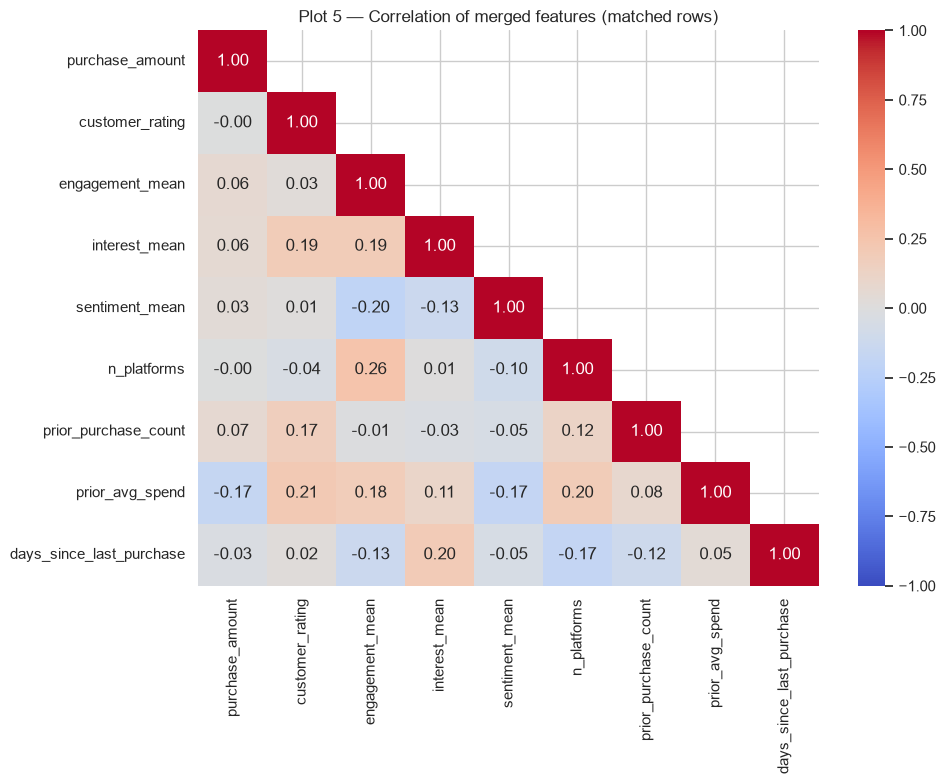

In [18]:
corr_cols = ["purchase_amount", "customer_rating", "engagement_mean", "interest_mean", "sentiment_mean",
             "n_platforms", "prior_purchase_count", "prior_avg_spend", "days_since_last_purchase"]
corr = merged.loc[merged["has_social_profile"], corr_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1,
            mask=np.triu(np.ones_like(corr, dtype=bool), k=1))  # lower triangle only, no repeats
plt.title("Plot 5 — Correlation of merged features (matched rows)")
plt.tight_layout(); plt.show()

**What I see:** every correlation is weak (|r| ≤ 0.26). The strongest pair is engagement and number of platforms (0.26): busier customers are on more platforms. No pair is redundant, so I keep all features. Nothing correlates strongly with spend either, which matches Plot 3.

### Plot 6 — Do customers repeat categories?

If people bought the same category again and again, `last_category` would be a powerful feature. The heatmap shows, for each previous category (row), what share of the next purchases went to each category (column).

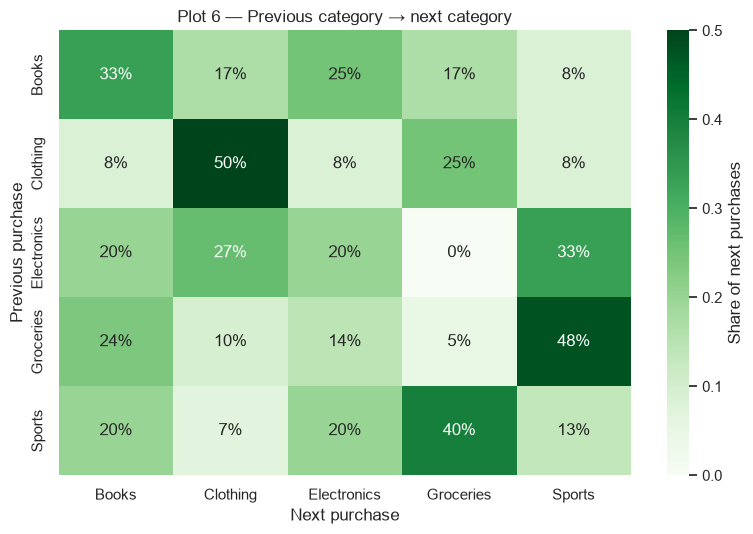

Repeat-purchase rate (same category as last time): 21.3%


In [19]:
repeat = merged.loc[merged["last_category"] != "None"]
transition = pd.crosstab(repeat["last_category"], repeat["product_category"], normalize="index")

plt.figure(figsize=(8, 5.5))
sns.heatmap(transition, annot=True, fmt=".0%", cmap="Greens", cbar_kws={"label": "Share of next purchases"})
plt.title("Plot 6 — Previous category → next category")
plt.xlabel("Next purchase"); plt.ylabel("Previous purchase")
plt.tight_layout(); plt.show()
print(f"Repeat-purchase rate (same category as last time): {(repeat['last_category'] == repeat['product_category']).mean():.1%}")

**What I see:** only 21% of repeat purchases are the same category as last time, which is about the rate of random guessing. A few cells stand out (Clothing → Clothing 50%, Groceries → Sports 48%), but each row is based on only 12–21 purchases. `last_category` might help a little; I won't rely on it.

## 10. Product Recommendation Model

**Framing:** 5-class classification (Books, Clothing, Electronics, Groceries, Sports).
**Population:** transactions **with a social profile**, because the model serves people visiting our social pages. Customers with no profile get a popularity-based fallback in the app instead of a model guess built on empty features.
**Holdout:** a stratified 20% test set is locked away until the very end. All model selection happens with repeated 5-fold CV on the remaining 80%.

In [20]:
SOCIAL_FEATURES = ["engagement_mean", "engagement_max", "interest_mean", "interest_max", "sentiment_mean",
                   "social_profile_rows", "n_platforms"] + list(platform_share.columns)
HISTORY_NUMERIC = ["prior_purchase_count", "prior_avg_spend", "prior_avg_rating", "days_since_last_purchase",
                   "visit_month", "visit_dayofweek"]
HISTORY_CATEGORICAL = ["last_category"]
NUMERIC_FEATURES_MODEL = SOCIAL_FEATURES + HISTORY_NUMERIC
FEATURES = NUMERIC_FEATURES_MODEL + HISTORY_CATEGORICAL
TARGET = "product_category"

model_df = merged.loc[merged["has_social_profile"]].reset_index(drop=True)
X, y = model_df[FEATURES], model_df[TARGET].astype(str)
CLASSES = sorted(y.unique())

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print(f"Modelling rows: {len(model_df)} | train: {len(X_train)} | test: {len(X_test)} | features: {len(FEATURES)}")
display(pd.DataFrame({"train": y_train.value_counts(), "test": y_test.value_counts()}))

Modelling rows: 117 | train: 93 | test: 24 | features: 19


,train,test
product_category,,
Books,16,4
Clothing,18,4
Electronics,21,6
Groceries,16,4
Sports,22,6


### Preprocessing pipeline + metrics

Numeric columns get a median imputer (plus a "was missing" flag) and are scaled. `last_category` is one-hot encoded. Everything sits in one `Pipeline`, so CV re-fits it inside every fold and nothing leaks. Metrics: **accuracy**, **macro-F1** (treats every category equally), **log loss** (penalises confident wrong answers), and **top-3 accuracy** (is the true product in our three recommendations?).

In [21]:
def make_preprocessor(numeric_cols, categorical_cols):
    numeric = Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=True)),
                        ("scale", StandardScaler())])
    categorical = OneHotEncoder(handle_unknown="ignore")
    return ColumnTransformer([("num", numeric, numeric_cols), ("cat", categorical, categorical_cols)])


SCORING = {
    "accuracy": "accuracy",
    "f1_macro": "f1_macro",
    "neg_log_loss": "neg_log_loss",
    "top3_accuracy": make_scorer(top_k_accuracy_score, k=3, labels=CLASSES, response_method="predict_proba"),
}
CV = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=RANDOM_STATE)  # 25 fits → steadier averages


def cv_summary(estimator, X_, y_):
    # Mean ± std of every metric across the 25 folds
    res = cross_validate(estimator, X_, y_, cv=CV, scoring=SCORING)
    out = {}
    for name in SCORING:
        vals = res[f"test_{name}"] * (-1 if name.startswith("neg_") else 1)
        key = name.replace("neg_", "")
        out[key], out[f"{key}_std"] = vals.mean(), vals.std()
    return out

### Model shoot-out (cross-validated on the training set)

I compare three real models against a **dummy baseline** that always predicts the most common category and gives every category its overall share as its probability. A model only earns its place by beating that dummy. XGBoost isn't installed in our environment, so `HistGradientBoosting`, scikit-learn's own gradient-boosted trees, stands in for the boosting family.

In [22]:
CANDIDATES = {
    "Baseline (class priors)": DummyClassifier(strategy="prior"),  # always the most common class, honest probabilities
    "Logistic Regression": LogisticRegression(C=0.1, max_iter=5000),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=3, random_state=RANDOM_STATE),
    "Gradient Boosting": HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, random_state=RANDOM_STATE),
}
results = pd.DataFrame({
    name: cv_summary(Pipeline([("prep", make_preprocessor(NUMERIC_FEATURES_MODEL, HISTORY_CATEGORICAL)), ("model", model)]),
                     X_train, y_train)
    for name, model in CANDIDATES.items()
}).T
display(results.round(3).sort_values("log_loss"))

,accuracy,accuracy_std,f1_macro,f1_macro_std,log_loss,log_loss_std,top3_accuracy,top3_accuracy_std
Random Forest,0.289,0.087,0.253,0.091,1.587,0.098,0.685,0.103
Baseline (class priors),0.215,0.006,0.071,0.002,1.604,0.009,0.656,0.021
Logistic Regression,0.295,0.067,0.262,0.073,1.635,0.126,0.689,0.097
Gradient Boosting,0.289,0.099,0.270,0.107,1.852,0.350,0.700,0.144


### Plot 7 — Model comparison

Bars are the mean across 25 CV folds and whiskers are ±1 standard deviation. The dashed line marks the dummy baseline. With a test fold of only ~19 rows, overlapping whiskers mean "not clearly different", so I weigh log loss and F1 together instead of crowning a winner on a 1% accuracy gap.

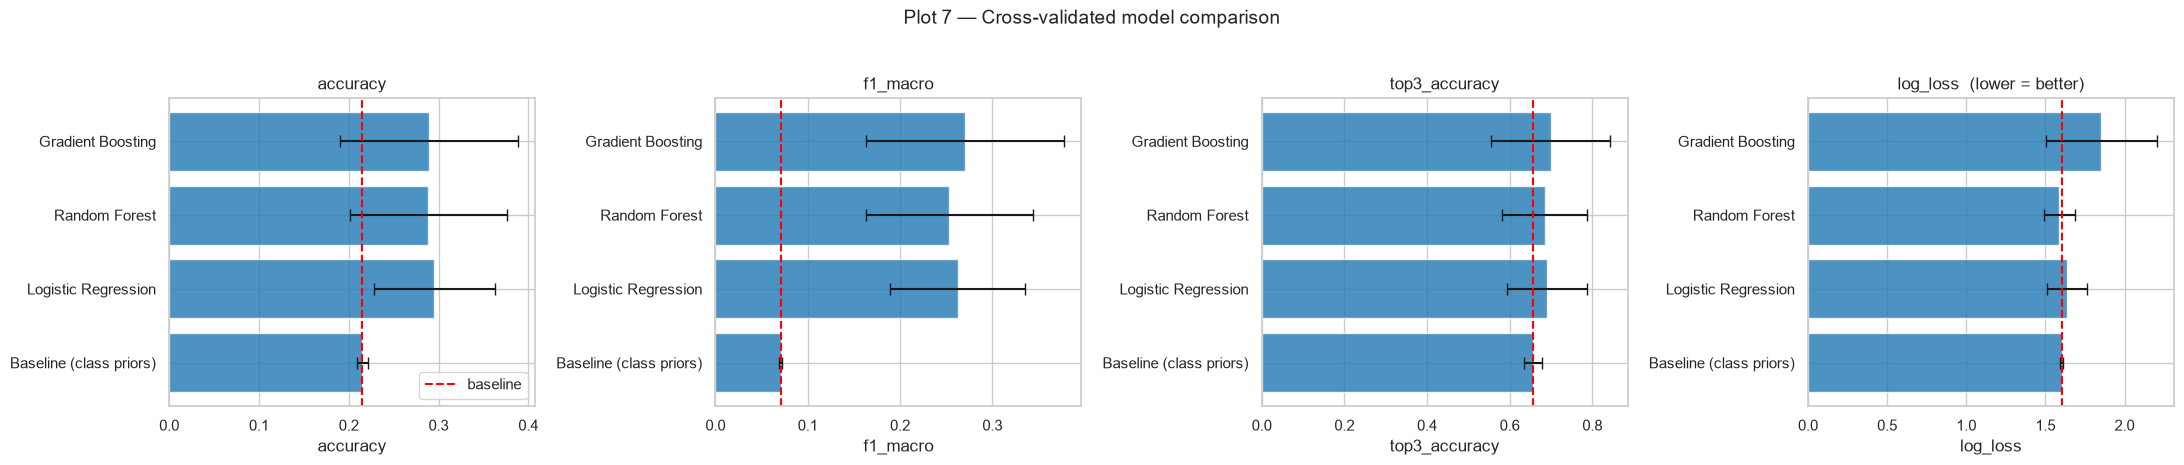

In [23]:
fig, axes = plt.subplots(1, 4, figsize=(22, 4.5))
for ax, metric in zip(axes, ["accuracy", "f1_macro", "top3_accuracy", "log_loss"]):
    ax.barh(results.index, results[metric], xerr=results[f"{metric}_std"], color="tab:blue", alpha=0.8, capsize=4)
    ax.axvline(results.loc["Baseline (class priors)", metric], ls="--", color="red", label="baseline")
    ax.set(title=metric + ("  (lower = better)" if metric == "log_loss" else ""), xlabel=metric)
axes[0].legend()
fig.suptitle("Plot 7 — Cross-validated model comparison", y=1.03, fontsize=14)
plt.tight_layout(); plt.show()

**What I see:** all three real models beat the baseline on accuracy (~29% vs 22%), macro-F1 (~0.26 vs 0.07) and top-3 accuracy (~0.69 vs 0.66). On log loss, though, only Random Forest (1.59) is better than the baseline's 1.60, and only barely. Gradient Boosting has the worst log loss and the largest spread: it is overconfident on so little data. Random Forest and Logistic Regression go to tuning.

### Ablation: which feature groups actually help?

This is my check on the leakage table in Section 9. I retrain the Random Forest with (a) social features only, (b) social + history (my design), and (c) my design **plus** the current purchase's amount and rating, the "cheating" features. If (c) barely helps, leaving them out costs us nothing.

In [24]:
rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=3, random_state=RANDOM_STATE)
LEAKY = ["purchase_amount", "customer_rating"]
X_train_leaky = model_df.loc[X_train.index, FEATURES + LEAKY]
ablation = {
    "(a) social only": (SOCIAL_FEATURES, [], X_train),
    "(b) social + history  ← chosen": (NUMERIC_FEATURES_MODEL, HISTORY_CATEGORICAL, X_train),
    "(c) + current purchase info (leaky)": (NUMERIC_FEATURES_MODEL + LEAKY, HISTORY_CATEGORICAL, X_train_leaky),
}
ablation_results = pd.DataFrame({
    name: cv_summary(Pipeline([("prep", make_preprocessor(num, cat)), ("model", rf)]), X_[num + cat], y_train)
    for name, (num, cat, X_) in ablation.items()
}).T
display(ablation_results[["accuracy", "f1_macro", "log_loss", "top3_accuracy"]].round(3))

,accuracy,f1_macro,log_loss,top3_accuracy
(a) social only,0.233,0.203,1.731,0.619
(b) social + history ← chosen,0.289,0.253,1.587,0.685
(c) + current purchase info (leaky),0.321,0.285,1.566,0.721


**What I see:** social features alone barely beat the baseline (accuracy 0.23). Adding purchase history is what lifts the model (0.29 accuracy, 0.69 top-3). The leaky extras add only ~3 accuracy points, and they wouldn't exist at prediction time anyway, so dropping them is the right call. The design holds up.

### Hyper-parameter tuning (small grid, scored by log loss)

I tune the two most sensible models, the Random Forest and Logistic Regression, and keep whichever has the better CV log loss. The grids are deliberately small: with ~90 training rows, a big search would just find settings that fit this particular CV noise.

In [25]:
SEARCHES = {
    "Random Forest": (RandomForestClassifier(random_state=RANDOM_STATE),
                      {"model__n_estimators": [300], "model__min_samples_leaf": [2, 4, 8],
                       "model__max_depth": [None, 5], "model__max_features": ["sqrt", 0.5]}),
    "Logistic Regression": (LogisticRegression(max_iter=5000), {"model__C": [0.01, 0.03, 0.1, 0.3, 1.0]}),
}
tuned = {}
for name, (model, grid) in SEARCHES.items():
    pipe = Pipeline([("prep", make_preprocessor(NUMERIC_FEATURES_MODEL, HISTORY_CATEGORICAL)), ("model", model)])
    search = GridSearchCV(pipe, grid, cv=CV, scoring="neg_log_loss").fit(X_train, y_train)
    tuned[name] = search
    print(f"{name:20s} best CV log loss = {-search.best_score_:.3f} with {search.best_params_}")

best_name = min(tuned, key=lambda n: -tuned[n].best_score_)
best_model = tuned[best_name].best_estimator_
print("\n→ Selected model:", best_name)

Random Forest        best CV log loss = 1.571 with {'model__max_depth': None, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 8, 'model__n_estimators': 300}


Logistic Regression  best CV log loss = 1.574 with {'model__C': 0.01}

→ Selected model: Random Forest


### Final exam: the untouched test set

Now, and only now, I score the chosen model on the 20% holdout it has never seen. The baseline gets scored on the same rows for a fair comparison.

In [26]:
def evaluate(model, X_, y_):
    proba = model.predict_proba(X_)
    pred = model.classes_[proba.argmax(axis=1)]
    return {"accuracy": accuracy_score(y_, pred), "f1_macro": f1_score(y_, pred, average="macro"),
            "log_loss": log_loss(y_, proba, labels=model.classes_),
            "top3_accuracy": top_k_accuracy_score(y_, proba, k=3, labels=model.classes_)}


baseline = Pipeline([("prep", make_preprocessor(NUMERIC_FEATURES_MODEL, HISTORY_CATEGORICAL)),
                     ("model", DummyClassifier(strategy="prior"))]).fit(X_train, y_train)
test_scores = pd.DataFrame({best_name: evaluate(best_model, X_test, y_test),
                            "Baseline (class priors)": evaluate(baseline, X_test, y_test)}).T
display(test_scores.round(3))
print(classification_report(y_test, best_model.predict(X_test), zero_division=0))

,accuracy,f1_macro,log_loss,top3_accuracy
Random Forest,0.333,0.281,1.596,0.750
Baseline (class priors),0.250,0.080,1.593,0.667


              precision    recall  f1-score   support

       Books       0.00      0.00      0.00         4
    Clothing       0.33      0.25      0.29         4
 Electronics       0.40      0.33      0.36         6
   Groceries       0.50      0.25      0.33         4
      Sports       0.31      0.67      0.42         6

    accuracy                           0.33        24
   macro avg       0.31      0.30      0.28        24
weighted avg       0.32      0.33      0.30        24



### Plot 8 — Confusion matrix on the test set

Rows are the real category and columns are what the model predicted. The diagonal shows correct predictions. Off-diagonal clusters show which categories the model mixes up.

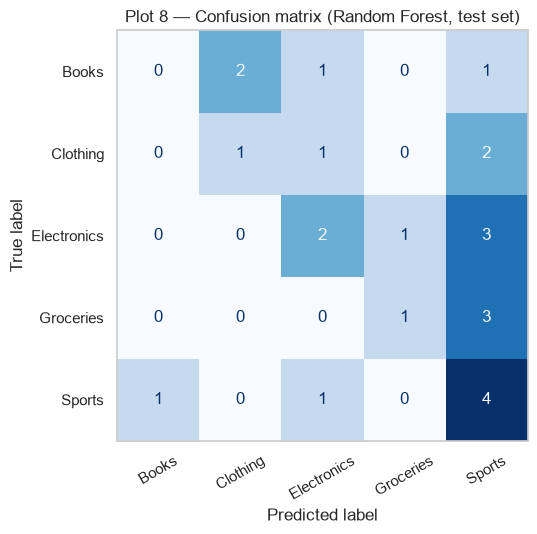

In [27]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
ConfusionMatrixDisplay.from_estimator(best_model, X_test, y_test, cmap="Blues", ax=ax, colorbar=False)
ax.set_title(f"Plot 8 — Confusion matrix ({best_name}, test set)"); ax.grid(False)
plt.xticks(rotation=30); plt.tight_layout(); plt.show()

**What I see:** the model favours **Sports**, predicting it for 13 of the 24 test rows, and never predicts Books correctly. On a dataset this weak, the model falls back toward the most common class when unsure. Electronics and Sports have the most correct predictions. With only 4–6 test rows per class, one row more or less changes recall by 17–25 points, so I read this matrix as a rough picture, not a final verdict.

### Plot 9 — Which features does the model lean on?

Permutation importance shuffles one feature at a time and measures how much the log loss gets worse. I compute it on the *training* rows (30 shuffles each), because the 24-row test set is too small for stable importances. That shows what the model *uses*, not proof of what drives purchases.

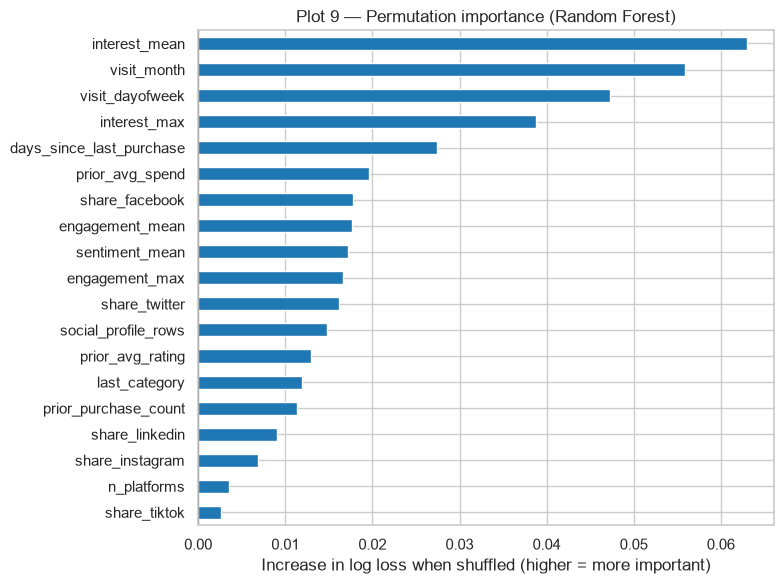

In [28]:
perm = permutation_importance(best_model, X_train, y_train, scoring="neg_log_loss",
                              n_repeats=30, random_state=RANDOM_STATE)
importance = pd.Series(perm.importances_mean, index=FEATURES).sort_values()

plt.figure(figsize=(8, 6))
importance.plot.barh(color=np.where(importance > 0, "tab:blue", "tab:gray"))
plt.axvline(0, color="black", lw=0.8)
plt.title(f"Plot 9 — Permutation importance ({best_name})")
plt.xlabel("Increase in log loss when shuffled (higher = more important)")
plt.tight_layout(); plt.show()

**What I see:** `interest_mean` (the customer's average purchase-interest score) matters most, so the social data does contribute. `visit_month` and `visit_dayofweek` rank high too, which makes me suspicious. These are training-set importances, and a forest can memorise date quirks, so I treat the timing features as "possibly overfit" rather than a real seasonal effect.

## 11. Ship it: refit on all data, save the model + a customer feature store

For deployment I refit the selected pipeline on **all** profile-matched rows: the holdout already did its job of giving an honest score. The CLI won't have a "transaction row" to predict from, only a customer ID. So I also build a **feature store** with each customer's latest state as of the next day after our data ends.

In [29]:
final_model = best_model.fit(X, y)
VISIT_DATE = merged["purchase_date"].max() + pd.Timedelta(days=1)

# Latest history per customer, computed over ALL their purchases
history = transactions.sort_values(["purchase_date", "transaction_id"]).groupby(KEY).agg(
    prior_purchase_count=("transaction_id", "size"), prior_avg_spend=("purchase_amount", "mean"),
    prior_avg_rating=("customer_rating", "mean"), last_category=("product_category", "last"),
    last_purchase_date=("purchase_date", "max")).reset_index()

store = profile_features.merge(history, on=KEY, how="outer")
store["has_social_profile"] = store[KEY].isin(profile_features[KEY])
store["prior_purchase_count"] = store["prior_purchase_count"].fillna(0).astype(int)
store["last_category"] = store["last_category"].fillna("None").astype(str)
store["days_since_last_purchase"] = (VISIT_DATE - store["last_purchase_date"]).dt.days
store["visit_month"], store["visit_dayofweek"] = VISIT_DATE.month, VISIT_DATE.dayofweek
store = store.drop(columns="last_purchase_date").sort_values(KEY)
store.to_csv(FEATURE_STORE_PATH, index=False)

MODEL_DIR.mkdir(exist_ok=True)
joblib.dump({
    "model": final_model, "model_name": best_name, "features": FEATURES, "classes": list(final_model.classes_),
    "fallback_distribution": y.value_counts(normalize=True).to_dict(),   # used when a customer has no profile
    "visit_date": str(VISIT_DATE.date()), "test_metrics": test_scores.loc[best_name].round(4).to_dict(),
    "sklearn_version": sklearn.__version__,
}, MODEL_PATH)
print(f"Saved {MODEL_PATH} and {FEATURE_STORE_PATH} ({len(store)} customers, visit date {VISIT_DATE.date()})")

Saved models\product_recommender.joblib and data\customer_feature_store.csv (98 customers, visit date 2024-05-30)


### Demo: what the CLI will call after the face check passes

`recommend_products(customer_id)` looks up the customer, runs the model, and returns the top 3 categories with probabilities. An unknown ID raises an error; the app turns that into **access denied**. A known customer without a social profile gets the popularity fallback, and the output says so.

In [30]:
def recommend_products(customer_id, top_k=3):
    row = store.loc[store[KEY] == int(customer_id)]
    if row.empty:
        raise KeyError(f"Customer {customer_id} is unknown")
    if not bool(row["has_social_profile"].iloc[0]):
        dist = pd.Series(y.value_counts(normalize=True))
        return dist.head(top_k).round(3).to_dict(), "popularity fallback (no social profile)"
    proba = pd.Series(final_model.predict_proba(row[FEATURES])[0], index=final_model.classes_)
    return proba.sort_values(ascending=False).head(top_k).round(3).to_dict(), best_name


no_profile_id = int(store.loc[~store["has_social_profile"], KEY].iloc[0])
for cid in [check_id, int(store.loc[store["has_social_profile"], KEY].iloc[5]), no_profile_id]:
    recs, source = recommend_products(cid)
    print(f"Customer {cid:>3} → {recs}  [{source}]")
try:
    recommend_products(999)
except KeyError as err:
    print("Customer 999 →", err, "→ ACCESS DENIED in the app")

Customer 125 → {'Electronics': 0.269, 'Books': 0.221, 'Sports': 0.21}  [Random Forest]
Customer 105 → {'Electronics': 0.27, 'Clothing': 0.215, 'Books': 0.204}  [Random Forest]
Customer 108 → {'Sports': 0.239, 'Electronics': 0.231, 'Clothing': 0.188}  [popularity fallback (no social profile)]
Customer 999 → 'Customer 999 is unknown' → ACCESS DENIED in the app


The same logic lives in `scripts/product_model.py`, so the command-line app can do:

```bash
python scripts/product_model.py --customer-id 155
```

or `from scripts.product_model import recommend_products` after the face model returns a match and before the voice step confirms it.

## 12. Conclusions, honestly

| Metric (held-out test, 24 rows) | Random Forest | Baseline |
|---|---|---|
| Accuracy | **0.33** | 0.25 |
| Macro-F1 | **0.28** | 0.08 |
| Top-3 accuracy | **0.75** | 0.67 |
| Log loss | 1.596 | 1.593 |

- **What worked:** the merge is clean and verified (150 → 150 rows, a many-to-one join, a hand spot-check), and the features respect time order, so nothing leaks from the future. The model beats a "guess the most popular" baseline on accuracy, F1 and top-3 accuracy, both in CV and on the holdout.
- **The honest bit:** the predicted probabilities are close to the class shares (test log loss ≈ baseline). The data barely separates the categories (Plots 1, 3, 5, 6), so I frame the output as **top-3 recommendations**: the right product is in our three suggestions 75% of the time.
- **Why the system still makes sense:** the product model decides *what to show*. The face and voice models decide *who is allowed to see it*. A weak recommender is a business problem, not a security hole, because security is enforced before and after it runs.
- **What I'd do with more time and data:** more transactions per customer (most have 1–2), real timestamps of each visit, product-level browsing data, and a time-based train/test split once there's enough history.